### Notebook for quick inference

In [ ]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

import os
from pathlib import Path

print("Current working directory:", Path.cwd())

repo_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
print("Repo root:", repo_root)

image_paths = list(repo_root.glob("data/**/*.jpg"))

Current working directory: d:\Projects\pet-classifier\notebooks
Repo root: d:\Projects\pet-classifier


In [29]:
# Load ResNet18 model with default weights in eval mode 
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

Loading sample image: beagle_1.jpg
Image shape before preprocess: (500, 400)


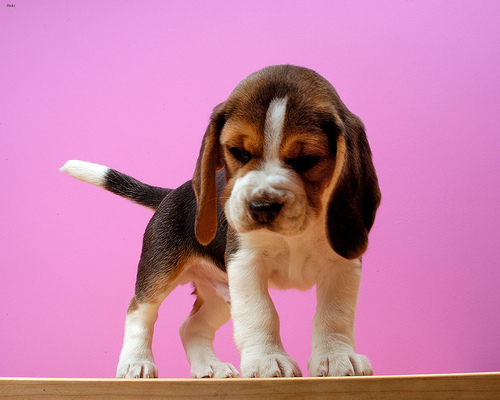

In [63]:
from PIL import Image

img_path = image_paths[800]
print(f"Loading sample image: {img_path.name}")

img = Image.open(img_path).convert("RGB")
print(f"Image shape before preprocess: {img.size}")
img

In [64]:
# Initialize the inference transforms
preprocess = weights.transforms()
# Apply inference preprocess transforms
batch = preprocess(img).unsqueeze(0)
# Run inference
with torch.no_grad():
    logits = model(batch)
    prediction = logits.squeeze(0).softmax(0)
    class_id = prediction.argmax().item()
    score = prediction[class_id].item()
    category_name = weights.meta["categories"][class_id]
    print(f"{category_name}: {100 * score:.1f}%")

beagle: 67.0%
